# Phase 2.2 — XGBoost Directional Forecasting

**Question:** Does nonlinear boosting improve out-of-sample probability estimates compared to an L2 Logistic Regression and a historical-prior baseline?

Run `python -m quant_trading.pipeline`, `python -m quant_trading.phase2_baselines`, then `python -m quant_trading.phase2_xgboost` **before** this notebook.

Only **train (2005–2018)** and **validation (2019–2021)** are accessed. **Never load held-out test (2022–2026) during model development.** All fits and parameter tuning live in `src/quant_trading/`.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

current_dir = Path.cwd().resolve()
for PROJECT_ROOT in (current_dir, *current_dir.parents):
    if (PROJECT_ROOT / "src" / "quant_trading" / "pipeline.py").is_file():
        break
else:
    raise FileNotFoundError("Start Jupyter inside the extracted project.")

REPORT_DIR = PROJECT_ROOT / "reports" / "phase2_2"
assert (REPORT_DIR / "config.json").is_file(), "Run python -m quant_trading.phase2_xgboost first"
config = json.loads((REPORT_DIR / "config.json").read_text(encoding="utf-8"))
print("Selected hyperparameters:", config["best_params"])
print("Test accessed:", config["test_used"])

Selected hyperparameters: {'max_depth': 2, 'min_child_weight': 15, 'n_estimators': 100}
Test accessed: False


## 1. Training-era walk-forward cross-validation

Eight predetermined configurations: `max_depth ∈ {2,3}`, `min_child_weight ∈ {5,15}` and `n_estimators ∈ {100,300}`. **Four expanding folds** (252 sessions each), **two-row gap** and explicit exit-date maturity checks. Select by lowest mean CV Log Loss.

,max_depth,min_child_weight,n_estimators,cv_log_loss,cv_log_loss_std,cv_brier_score,cv_roc_auc
0,2,15,100,0.696033,0.009639,0.251372,0.481712
1,2,5,100,0.696253,0.009462,0.251494,0.477811
2,3,15,100,0.698566,0.011878,0.252593,0.480267
3,3,5,100,0.699203,0.009938,0.252912,0.489799
4,2,15,300,0.704238,0.015068,0.255336,0.477977
5,2,5,300,0.705250,0.013533,0.255799,0.476829
6,3,15,300,0.712116,0.016152,0.258898,0.483335
7,3,5,300,0.715814,0.011139,0.260599,0.484708


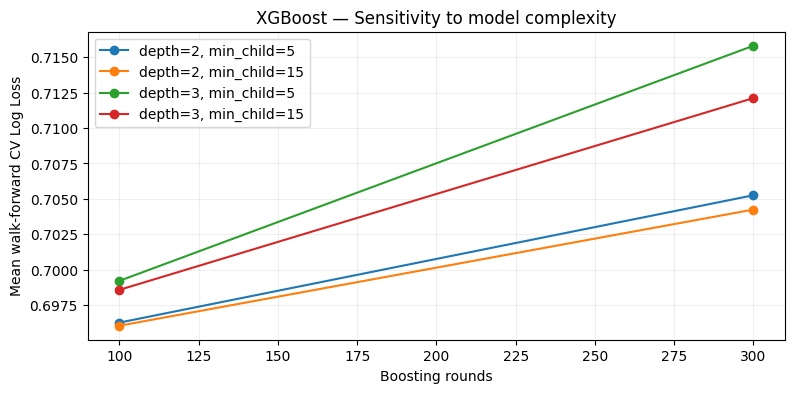

In [2]:
folds = pd.read_csv(REPORT_DIR / "cv_folds.csv")
summary = pd.read_csv(REPORT_DIR / "cv_summary.csv").sort_values("cv_log_loss")
display(summary)
assert len(summary) == 8 and len(folds) == 32
fig, ax = plt.subplots(figsize=(9, 4))
for (depth, child_weight), part in summary.groupby(["max_depth", "min_child_weight"]):
    part = part.sort_values("n_estimators")
    ax.plot(part["n_estimators"], part["cv_log_loss"], marker="o",
            label=f"depth={depth}, min_child={child_weight}")
ax.set(xlabel="Boosting rounds", ylabel="Mean walk-forward CV Log Loss",
       title="XGBoost — Sensitivity to model complexity")
ax.grid(alpha=.2)
ax.legend()
plt.show()

## 2. Selected model — validation results

The chosen configuration is refitted on all **purged 2005–2018 training rows**. Compare the same signal dates, label definition and 17 features as Phase 2.1. Prior model predictions are loaded from the baseline script, not refitted on validation.

In [3]:
metrics = pd.read_csv(REPORT_DIR / "validation_metrics.csv")
train_val = pd.read_csv(REPORT_DIR / "train_vs_validation_metrics.csv")
pred = pd.read_csv(REPORT_DIR / "validation_predictions.csv",
                   parse_dates=["signal_date"]).set_index("signal_date")
display(metrics[["model", "log_loss", "brier_score", "roc_auc",
                 "mean_predicted_probability", "observed_positive_rate"]])
display(train_val[["split", "log_loss", "brier_score", "roc_auc"]])
assert pred.index.is_unique and pred.index.is_monotonic_increasing
assert pred.index.max() < pd.Timestamp("2022-01-01")
assert all(pred[c].between(0, 1).all() for c in ("p_baseline", "p_logistic", "p_xgboost"))

,model,log_loss,brier_score,roc_auc,mean_predicted_probability,observed_positive_rate
0,Constant Probability,0.679269,0.243076,0.500000,0.544534,0.6
1,XGBoost,0.686009,0.246405,0.495446,0.536631,0.6
2,Logistic Regression,0.687180,0.246934,0.486930,0.538449,0.6


,split,log_loss,brier_score,roc_auc
0,train,0.669737,0.238424,0.658537
1,validation,0.686009,0.246405,0.495446


## 3. Probability distributions and calibration

A sharper predictive distribution is not automatically better. Assess calibration and log loss, not solely ROC-AUC or a larger distance from 0.5. Reliability-diagram bins can be noisy when labels are scarce.

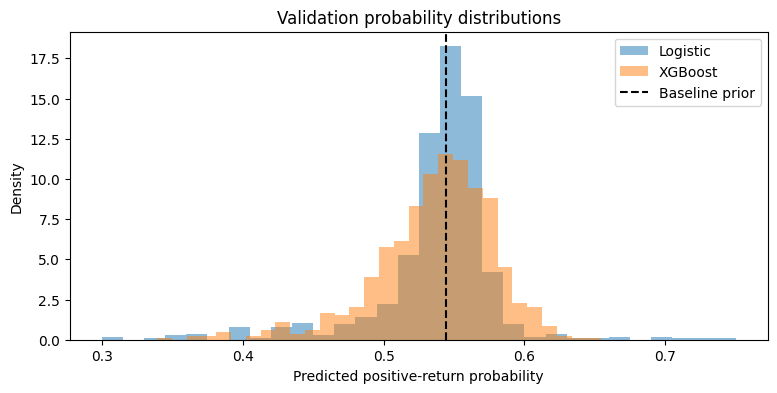

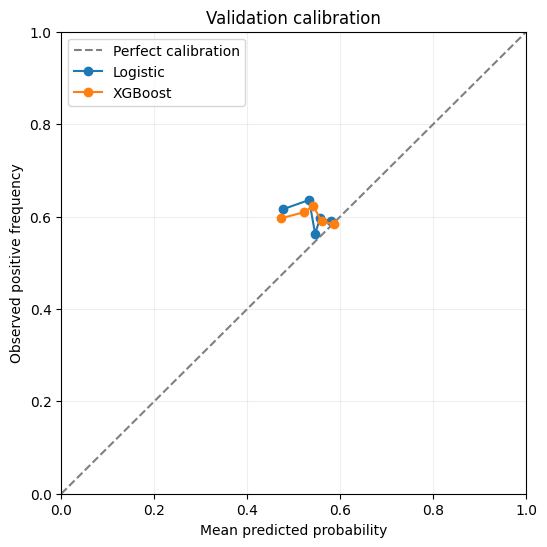

In [4]:
from sklearn.calibration import calibration_curve
fig, ax = plt.subplots(figsize=(9, 4))
for name, col in [("Logistic", "p_logistic"), ("XGBoost", "p_xgboost")]:
    ax.hist(pred[col], bins=30, alpha=.5, density=True, label=name)
ax.axvline(pred["p_baseline"].mean(), ls="--", color="black", label="Baseline prior")
ax.set(xlabel="Predicted positive-return probability", ylabel="Density",
       title="Validation probability distributions")
ax.legend()
plt.show()

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot([0,1],[0,1],"--", color="gray", label="Perfect calibration")
for name, col in [("Logistic", "p_logistic"), ("XGBoost", "p_xgboost")]:
    observed, predicted = calibration_curve(pred["actual_label"], pred[col],
                                            n_bins=5, strategy="quantile")
    ax.plot(predicted, observed, marker="o", label=name)
ax.set(xlim=(0,1), ylim=(0,1), xlabel="Mean predicted probability",
       ylabel="Observed positive frequency", title="Validation calibration")
ax.grid(alpha=.2)
ax.legend()
plt.show()

## 4. Feature importance — descriptive only

Gain importance reflects the XGBoost training objective. Correlated indicators can substitute for each other; gain **is not** an estimate of causal effect, nor independent out-of-sample feature importance.

,feature,gain
0,macd_hist_norm,6.544683
1,ema_gap_12,6.326514
2,rsi_14,6.062458
3,vol_63d,6.043671
4,ema_gap_26,5.956874
5,relative_volume_20,5.950639
6,vol_21d,5.625458
7,ret_lag_1,5.496889
8,macd_norm,5.369992
9,momentum_21d,5.229560


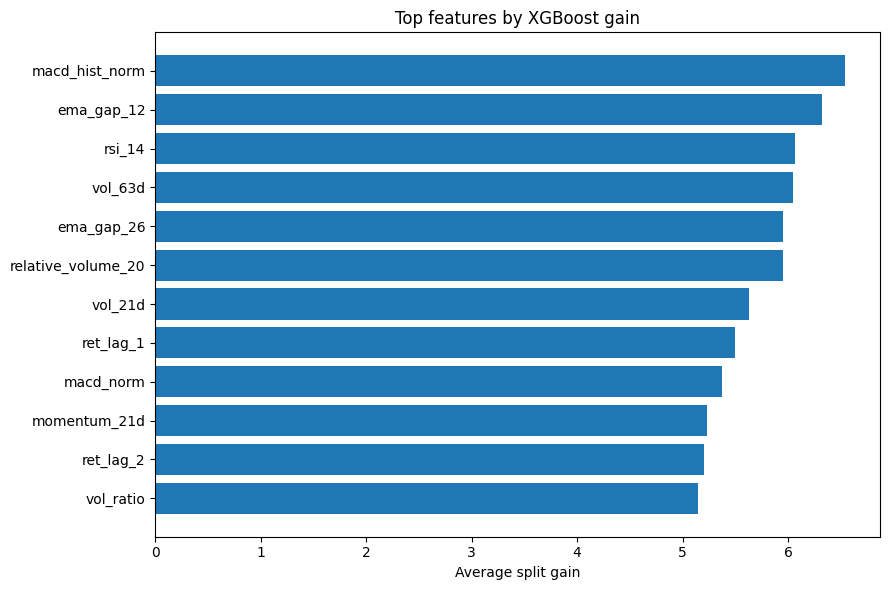

In [5]:
gain = pd.read_csv(REPORT_DIR / "feature_gain.csv")
display(gain.head(17))
fig, ax = plt.subplots(figsize=(9, 6))
top = gain.head(12).iloc[::-1]
ax.barh(top["feature"], top["gain"])
ax.set(xlabel="Average split gain", title="Top features by XGBoost gain")
plt.tight_layout()
plt.show()

## Does boosting improve the forecasts?

- **Comparison.** The selected configuration (depth 2, minimum child weight 15, 100 trees) has validation Log Loss 0.68601. This is 0.00117 lower than logistic regression and 0.00674 higher than the constant prior. Notebook 04 estimates the uncertainty around those differences.
- **Generalization.** Train-to-validation Log Loss rises from 0.66974 to 0.68601. The change in ranking ability is more pronounced: AUC falls from 0.659 to 0.495. The ordering learned in training does not carry over to these dates.
- **Calibration.** Each validation quintile contains 151 days. In the lowest group, XGBoost predicts 47.26% up days and 59.60% occur. In the highest group the figures are 58.71% and 58.28%. The clearest error is excessive confidence in a downward move in the lowest group. The upper group is close to its observed frequency.
- **Interpretation.** MACD histogram and the 12-session EMA gap have the highest training gain. This measures how the fitted trees used those features. It does not establish a stable relationship on future dates.